In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
fashion_train_df = pd.read_csv('../datasets/fashion-mnist/fashion-mnist_train.csv', sep=',')
fashion_test_df = pd.read_csv('../datasets/fashion-mnist/fashion-mnist_test.csv', sep=',')

In [3]:
fashion_train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
fashion_train_df.tail()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
59995,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,1,0,0,0,0,0,0,0,0,0,...,73,0,0,0,0,0,0,0,0,0
59997,8,0,0,0,0,0,0,0,0,0,...,160,162,163,135,94,0,0,0,0,0
59998,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59999,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
fashion_train_df.shape

(60000, 785)

In [6]:
fashion_test_df.shape

(10000, 785)

In [7]:
training = np.array(fashion_train_df, dtype = 'float32')

In [8]:
testing = np.array(fashion_test_df, dtype = 'float32')

np.float32(3.0)

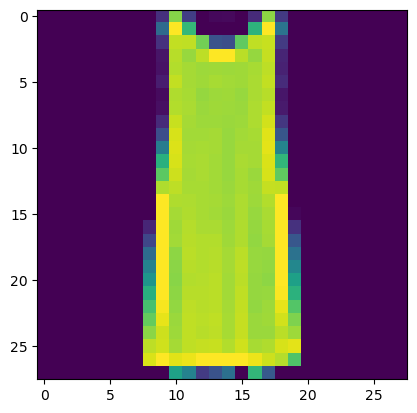

In [9]:
import random
i = random.randint(1, 60000)
plt.imshow(training[i, 1:].reshape(28, 28))
label = training[i, 0]
label

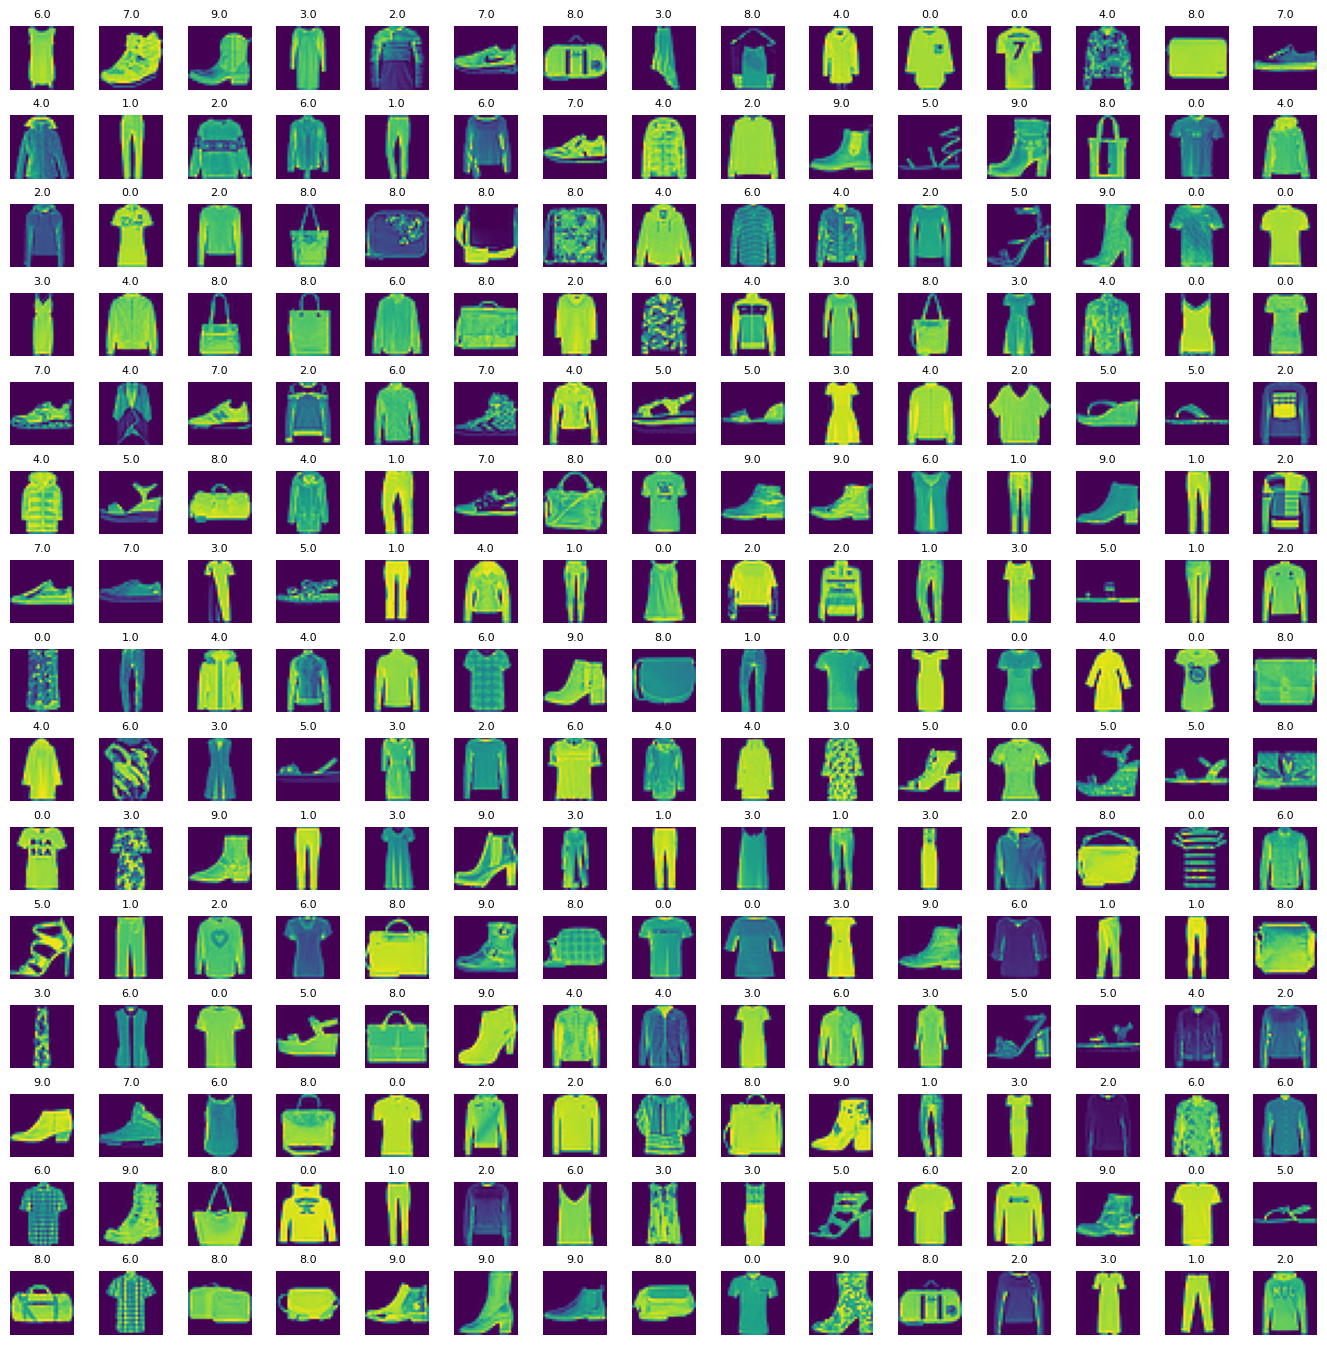

In [10]:
# Let's view more images in a grid format
# Define the dimensions of the plot grid
W_grid = 15
L_grid = 15

# fig, axes = plt.subplots(L_grid, W_grid)
# subplot return the figure object and axes object
# we can use the axes object to plot specific figures at various locations

fig, axes = plt.subplots(L_grid, W_grid, figsize = (17,17))

axes = axes.ravel() # flatten the 15 x 15 matrix into 225 array

n_training = len(training) # get the length of the training dataset

# Select a random number from 0 to n_training
for i in np.arange(0, W_grid * L_grid): # create evenly spaced variables

    # Select a random number
    index = np.random.randint(0, n_training)
    # read and display an image with the selected index
    axes[i].imshow( training[index,1:].reshape((28,28)) )
    axes[i].set_title(training[index,0], fontsize = 8)
    axes[i].axis('off')

plt.subplots_adjust(hspace=0.4)

In [14]:
X_train = training[:, 1:]/255
y_train = training[:, 0]

In [15]:
X_test = testing[:, 1:]/255
y_test = testing[:, 0]

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X_train, X_validate, y_train, y_validate = train_test_split(X_train, y_train, test_size = 0.2, random_state = 12345)

In [18]:
X_train = X_train.reshape(X_train.shape[0], *(28, 28, 1))
X_test = X_test.reshape(X_test.shape[0], *(28, 28, 1))
X_validate = X_validate.reshape(X_validate.shape[0], *(28, 28, 1))

In [20]:
X_train.shape

(48000, 28, 28, 1)

In [21]:
X_test.shape

(10000, 28, 28, 1)

In [22]:
X_validate.shape

(12000, 28, 28, 1)

In [29]:
import keras

In [30]:

from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout
from keras.optimizers import Adam
from keras.callbacks import TensorBoard

In [31]:
cnn_model = Sequential()

In [32]:
cnn_model.add(Conv2D(32, 3, 3, input_shape = (28, 28, 1), activation = 'relu'))

C:\Users\hp\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
cnn_model.add(MaxPooling2D(pool_size = (2,2)))


In [34]:
cnn_model.add(Flatten())

In [37]:
# Au lieu de output_dim = 32
cnn_model.add(Dense(units = 32, activation = 'relu'))

In [38]:
cnn_model.add(Dense(units = 10, activation = 'sigmoid'))

In [43]:
cnn_model.compile(loss='sparse_categorical_crossentropy', optimizer=Adam(learning_rate=0.001), metrics=['accuracy'])

In [44]:
epochs = 50

In [46]:
cnn_model.fit(X_train, y_train, batch_size = 512, epochs = epochs, verbose = 1, validation_data = (X_validate, y_validate))

Epoch 1/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.5703 - loss: 1.4145 - val_accuracy: 0.7267 - val_loss: 0.7771
Epoch 2/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7517 - loss: 0.6867 - val_accuracy: 0.7759 - val_loss: 0.6213
Epoch 3/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7849 - loss: 0.5944 - val_accuracy: 0.7940 - val_loss: 0.5658
Epoch 4/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8000 - loss: 0.5506 - val_accuracy: 0.8098 - val_loss: 0.5324
Epoch 5/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8096 - loss: 0.5209 - val_accuracy: 0.8114 - val_loss: 0.5185
Epoch 6/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8175 - loss: 0.4984 - val_accuracy: 0.8171 - val_loss: 0.5042
Epoch 7/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8244 - loss: 0.4810 - val_accuracy: 0.8288 - val_loss: 0.4815
Epoch 8/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8310 - loss: 0.4651 - val_accuracy: 0.8316 - v

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


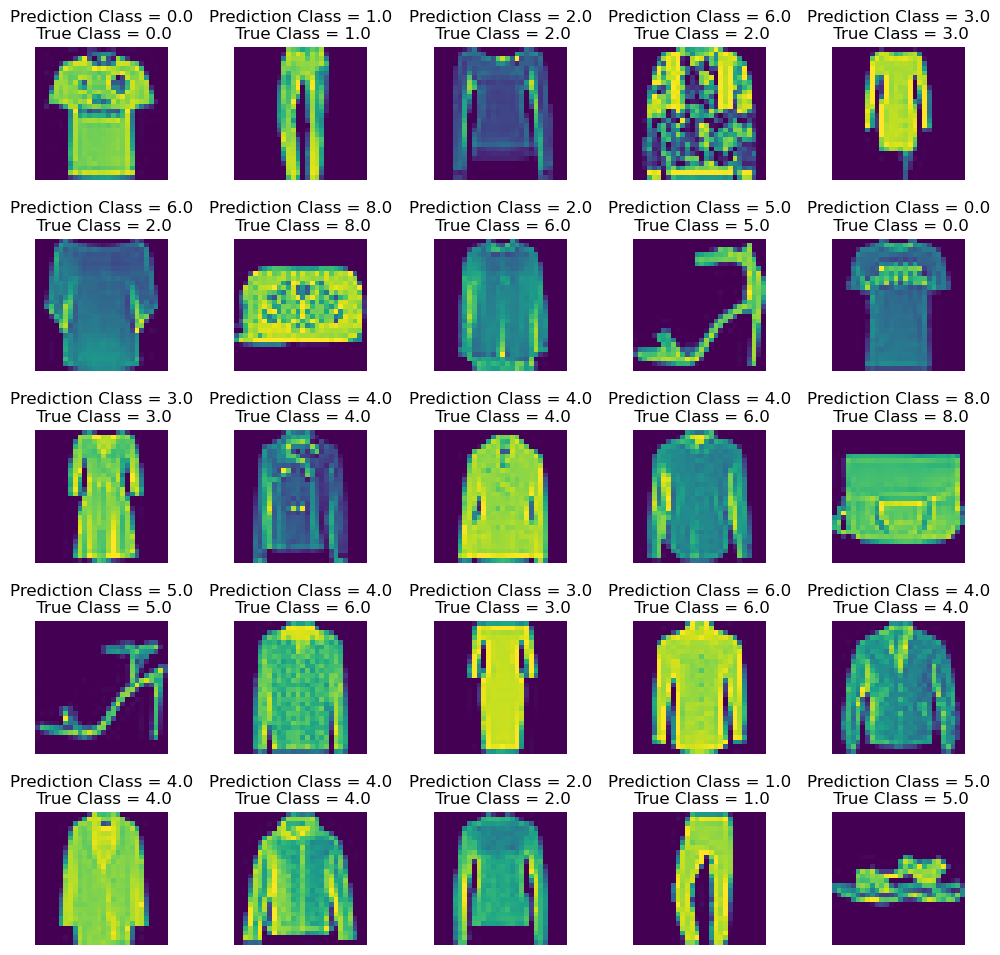

In [49]:
predicted_classes = np.argmax(cnn_model.predict(X_test), axis=1)

predicted_classes

L = 5
W = 5
fig, axes = plt.subplots(L, W, figsize = (12,12))  # J'ai aussi corrigé le 'l' minuscule en 'L' majuscule
axes = axes.ravel()

for i in np.arange(0, L * W):
    axes[i].imshow(X_test[i].reshape(28,28))
    axes[i].set_title("Prediction Class = {:0.1f}\n True Class = {:0.1f}".format(predicted_classes[i], y_test[i]))
    axes[i].axis('off')

plt.subplots_adjust(wspace=0.5)

<Axes: >

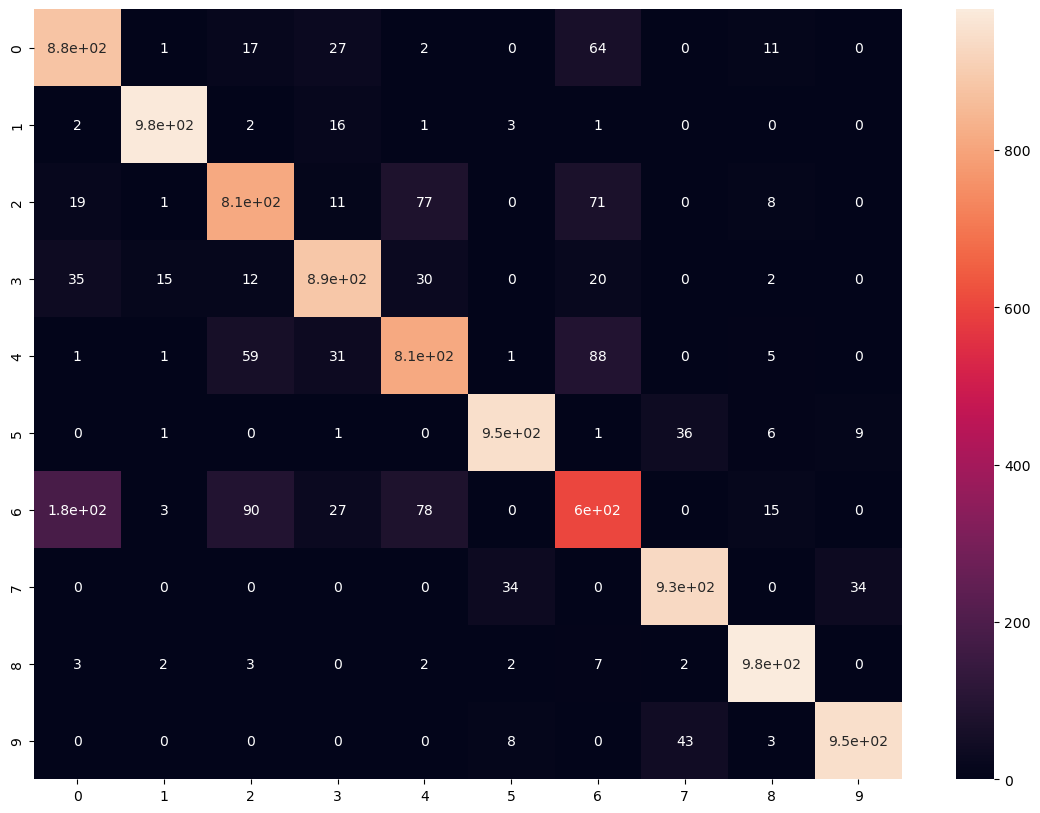

In [50]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, predicted_classes)
plt.figure(figsize = (14,10))
sns.heatmap(cm, annot=True)

In [52]:
from sklearn.metrics import classification_report
num_classes = 10
target_names = [f"Class {i}" for i in range(num_classes)]
print(classification_report(y_test, predicted_classes, target_names = target_names))

              precision    recall  f1-score   support

     Class 0       0.78      0.88      0.83      1000
     Class 1       0.98      0.97      0.98      1000
     Class 2       0.82      0.81      0.81      1000
     Class 3       0.89      0.89      0.89      1000
     Class 4       0.81      0.81      0.81      1000
     Class 5       0.95      0.95      0.95      1000
     Class 6       0.70      0.60      0.65      1000
     Class 7       0.92      0.93      0.93      1000
     Class 8       0.95      0.98      0.97      1000
     Class 9       0.96      0.95      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000

